# 02 — Preprocessing

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri, [arXiv:1901.02495](https://arxiv.org/abs/1901.02495))

## 1. Introduction

Long-term acoustic monitoring produces more audio than anyone can listen to, which is why the
article this project replicates proposes an automatic detector: a Gaussian mixture model per frog
species, trained on labelled calls and used to estimate which species are present in hours of
unattended field recordings. A classifier of that kind never sees audio. It sees a matrix of
numbers, and the quality of what it learns is decided before training begins, by the chain that
turns a recorded vocalisation into that matrix. This notebook builds that chain.

Notebook 01 audited the three delivered collections and established which of them carries labels
and which does not. The conclusion that governs everything here is that the pond recordings, which
are the article's test material, arrived without the presence-absence annotations that make them a
test set, and those annotations cannot be reconstructed without an expert identifying species by
ear. The preprocessing is therefore developed on the labelled call corpus published by the authors,
and that corpus is later divided into training and validation parts by this replication rather than
by the article.

In this notebook the objective is a faithful implementation of the article's front-end, not an improved one. Where
the article specifies a value, that value is used; where it is silent, a decision is taken, marked
as this replication's rather than the article's, and recorded so that it can be revisited. Improvements — resampling the mixed-rate corpus,
splitting by recording instead of by call — are deliberately left out of the main chain and noted as
separate experiments for later, so that the replication and the departures from it never share a
result.

The notebook follows the signal. Section 2 states which part of the delivered data is used and why.
Sections 3 and 4 open audio for the first time, cutting the annotated calls and checking every cut.
Section 5 records the decision not to resample and contains no code by design. Sections 6 to 10
implement the article's extraction chain one stage at a time — pre-emphasis, framing and windowing,
the discrete Fourier transform, the modified filter bank, and the logarithm and cosine transform
that yield the cepstral coefficients — each demonstrated on a single real call. Section 11 runs the
whole chain over the corpus to produce the feature matrix and its labels, section 12 writes them to
disk for the modelling step, and section 13 states what the notebook delivers and the limitations it
carries.

Claims are tagged `[PAPER]` (stated in the article), `[OBSERVED]` (measured here, and visible in the
output of the cell above it) and `[INFERENCE]` (plausible but not provable from the data).

In [1]:
# Every dependency this notebook uses, declared once. Standard library first, then
# third-party packages, then the helpers extracted from the first notebook.
import os
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from dotenv import load_dotenv
from numpy.lib.stride_tricks import sliding_window_view
from scipy.fft import dct
from scipy.io import loadmat

from frog_presence.audio import probe_audio_header

In [2]:
# Configuration: plotting style, the dataset location read from .env, the random seed
# that makes the split reproducible, and display options. Nothing here reads the data.

sns.set_theme(style="ticks")

# The audio lives outside the repository, in a different place on every machine, so the
# location is read from a local .env file instead of being written into the code.
load_dotenv()


def dataset_dir(variable: str) -> Path:
    """Read one dataset location from the environment.

    Args:
        variable (str): Name of the variable defined in .env, e.g. "MENDELEY_CALL_DIR".

    Returns:
        Path: The configured directory.

    Raises:
        RuntimeError: If the variable is missing, so the failure explains itself rather
            than surfacing as a bare KeyError.
    """
    value = os.environ.get(variable)
    if not value:
        raise RuntimeError(
            f"{variable} is not set. Copy .env.example to .env and fill in the paths "
            "to your local copies of the three collections."
        )
    return Path(value)


MENDELEY_CALL_DIR = dataset_dir("MENDELEY_CALL_DIR")
SEGMENT_DIR = MENDELEY_CALL_DIR / "segment files"
SEED = 20260814

# Only the folder names are printed: the full path is personal to whoever runs the notebook.
for path in (MENDELEY_CALL_DIR, SEGMENT_DIR):
    print(f"{'OK ' if path.is_dir() else 'MISSING'}  {path.name}")

pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 120)

OK   mendeley
OK   segment files


## 2. Which part of the delivered data is used, and why

**What this section asks, and why it matters.** Three collections were delivered, and notebook 01
established what each one contains. Only one of them can support the work in this notebook, and
saying which one and on what grounds is the first thing a reader needs.

The article trains on labelled frog calls and tests on pond recordings. The labels that make the
pond material a test set — a ten-variable presence-absence vector per sample — were not delivered,
and producing them requires an expert identifying ten species by ear, so that part of the article
cannot be reproduced here. What was delivered is the training corpus itself, published by the
authors on Mendeley Data, and it arrives with the annotation that delimits every individual call.

| Collection | Contents | Used here |
|---|---|---|
| `MENDELEY_CALL_DIR` — species folders | WAV recordings, one folder per species | **Yes**, as the audio source |
| `MENDELEY_CALL_DIR` — `segment files` | Ten `.mat` files holding call boundaries | **Yes**, as the annotation |
| `MENDELEY_CALL_DIR` — `Unidentified Long Recordings` | 47 unlabelled recordings | No — no species label |
| `MENDELEY_CALL_DIR` — `.rtf` cue points | Coarse sections containing calls | No — notebook 01 showed these mark passages, not individual calls |
| `PONDS_CALL_DIR` | 141 ten-minute pond samples | No — the presence-absence labels were not delivered |
| `SPECIES_CALL_DIR` | Clean species calls | No — no per-call boundaries |

`[PAPER]` Table 1 of the article reports the corpus it worked from. These are its published
figures, quoted here so that the measured ones below have something to be read against:

| Code | Species | Calls | Seconds | Frequency range (Hz) |
|---|---|---|---|---|
| f01 | *Boana alfaroi* | 98 | 44.70 | 1660–3100 |
| f02 | *Dendropsophus bifurcus* | 103 | 53.10 | 2300–3390 |
| f03 | *Boana cinerascens* | 169 | 105.50 | 1300–1530 |
| f04 | *Pristimantis conspicillatus* | 186 | 78.00 | 1630–3900 |
| f05 | *Leptodactylus discodactylus* | 330 | 146.30 | 1680–3260 |
| f06 | *Osteocephalus fuscifacies* | 50 | 23.52 | 1000–2500 |
| f07 | *Boana lanciformis* | 97 | 57.70 | 500–2720 |
| f08 | *Rhinella margaritifera* | 108 | 124.20 | 800–1700 |
| f09 | *Dendropsophus parviceps* | 38 | 40.10 | 5660–7500 |
| f10 | *Engystomops petersi* | 316 | 137.20 | 430–3140 |
| | **Total** | **1495** | **810.32** | |

The cell below reads the ten segment files and reports, for each species, how much of that is
present as audio on disk.

In [3]:
# What each segment file delimits, and how much of it has audio behind it on disk.
PAPER_TABLE1 = pd.DataFrame(
    [("f01", "Boana alfaroi", 98, 44.70, "cantos_alfaroi.mat"),
     ("f02", "Dendropsophus bifurcus", 103, 53.10, "cantos_bifurcus.mat"),
     ("f03", "Boana cinerascens", 169, 105.50, "cantos_cinerascens.mat"),
     ("f04", "Pristimantis conspicillatus", 186, 78.00, "cantos_conspicillatus.mat"),
     ("f05", "Leptodactylus discodactylus", 330, 146.30, "cantos_discodactylus.mat"),
     ("f06", "Osteocephalus fuscifacies", 50, 23.52, "cantos_fuscifacies.mat"),
     ("f07", "Boana lanciformis", 97, 57.70, "cantos_lanciformis.mat"),
     ("f08", "Rhinella margaritifera", 108, 124.20, "cantos_margaritifer.mat"),
     ("f09", "Dendropsophus parviceps", 38, 40.10, "cantos_parviceps.mat"),
     ("f10", "Engystomops petersi", 316, 137.20, "cantos_petersi.mat")],
    columns=["code", "species", "paper_calls", "paper_seconds", "segment_file"])

# Every WAV in the collection, indexed by lowercased name: the .mat files spell some
# recordings in a different case than the disk does.
WAV_ON_DISK = {path.name.lower(): path
               for path in MENDELEY_CALL_DIR.rglob("*") if path.suffix.lower() == ".wav"}


def read_calls(filename: str) -> pd.DataFrame:
    """Every call a segment file delimits, one per row.

    Args:
        filename (str): File name inside the `segment files` folder.

    Returns:
        pandas.DataFrame: Columns segment_file, recording, wav, rate, start, end.
            `recording` is the row position inside `cantos`, so two recordings stay
            distinct even if they carry the same file name. Offsets are in samples.
    """
    rows = []
    for position, (path, intervals, rate) in enumerate(loadmat(SEGMENT_DIR / filename)["cantos"]):
        wav = Path(str(path[0]).replace("\\", "/")).name
        for start, end in intervals:
            rows.append({"segment_file": filename, "recording": position, "wav": wav,
                         "rate": int(rate[0][0]), "start": int(start), "end": int(end)})
    return pd.DataFrame(rows)


# One table for the whole corpus: every call of every species, carrying the recording it
# was cut from and the rate that recording was sampled at.
annotated = pd.concat([read_calls(name) for name in PAPER_TABLE1.segment_file], ignore_index=True)
annotated = annotated.merge(PAPER_TABLE1[["segment_file", "code", "species"]], on="segment_file")
annotated["seconds"] = (annotated.end - annotated.start) / annotated.rate
annotated["on_disk"] = annotated.wav.str.lower().isin(WAV_ON_DISK)

# Only calls whose recording was delivered can become training material, so the summary
# is built from that subset and not from everything the annotation declares.
available = (annotated[annotated.on_disk].groupby("code")
             .agg(recordings=("recording", "nunique"), calls=("start", "size"),
                  seconds=("seconds", "sum")))

corpus = (PAPER_TABLE1.set_index("code")[["species", "paper_calls", "paper_seconds"]]
          .join(available).fillna(0))
corpus[["recordings", "calls"]] = corpus[["recordings", "calls"]].astype(int)

# A totals row, so the corpus can be read against the 1495 calls of Table 1 at a glance.
totals = corpus.sum(numeric_only=True).to_frame("TOTAL").T
totals["species"] = ""
shown = pd.concat([corpus, totals[corpus.columns]]).round(2)
shown[["recordings", "paper_calls", "calls"]] = shown[["recordings", "paper_calls", "calls"]].astype(int)

print("calls delimited by the segment files:", len(annotated),
      "- with audio on disk:", int(annotated.on_disk.sum()), "\n")
shown

calls delimited by the segment files: 1510 - with audio on disk: 1461 



,species,paper_calls,paper_seconds,recordings,calls,seconds
f01,Boana alfaroi,98,44.70,5,98,44.72
f02,Dendropsophus bifurcus,103,53.10,10,99,41.72
f03,Boana cinerascens,169,105.50,8,169,102.58
f04,Pristimantis conspicillatus,186,78.00,9,186,77.94
f05,Leptodactylus discodactylus,330,146.30,3,340,114.36
f06,Osteocephalus fuscifacies,50,23.52,5,54,24.94
f07,Boana lanciformis,97,57.70,7,101,57.84
f08,Rhinella margaritifera,108,124.20,7,96,102.66
f09,Dendropsophus parviceps,38,40.10,1,2,1.18
f10,Engystomops petersi,316,137.20,12,316,134.00


`[OBSERVED]` The segment files delimit **1510 calls**, of which **1461 have audio on disk**. The
missing ones all belong to `f09` *Dendropsophus parviceps*, which is left with **2 calls and 1.18
seconds** against the 38 calls and 40.1 s the article reports for it.

`[OBSERVED]` The nine remaining species hold between **24.94 s** (`f06`) and **134.00 s** (`f10`) of
delimited calls, for **701.94 s** in total.

`[PAPER]` The article states that *"Nine species had enough acoustic material, from 40 to 146
seconds of calls, that allowed the creation of training-validation subsets"*, and that `f06` was
added on top of those nine to obtain a model for the testing stage.

`[INFERENCE]` A nine-species corpus can be assembled here as well, but it is not the same nine. The
article's nine excluded `f06`; the nine available here exclude `f09`, whose audio was not published.
Every result obtained later is therefore comparable to the article in form but not in composition.

## 3. From annotation to audio: cutting one call

**What this section asks, and why it matters.** Everything so far has been read from annotation
files. This is the first step that opens audio, and the chain it starts is the whole of the
preprocessing:

```text
WAV recording
  → [start, end] interval from the .mat
  → the call, cut out
  → validation of the cut
  → pre-emphasis
  → framing and overlap
  → Hamming window
  → DFT
  → filter bank
  → log
  → DCT
  → cepstral coefficients
  → feature matrix X and labels y
  → training / validation split
```

The interval is a pair of sample offsets, so cutting is a slice, not a search. Reading only the
requested range keeps the whole recording out of memory, which matters because the corpus holds
recordings of several minutes and only fractions of a second of them are calls.

species        : f01 Boana alfaroi
recording      : 1101.WAV
interval       : 20598 to 37356 samples
samples read   : 16758 ( expected 16758 )
sample rate    : 44100 Hz
duration       : 0.38 s
peak amplitude : 0.1003


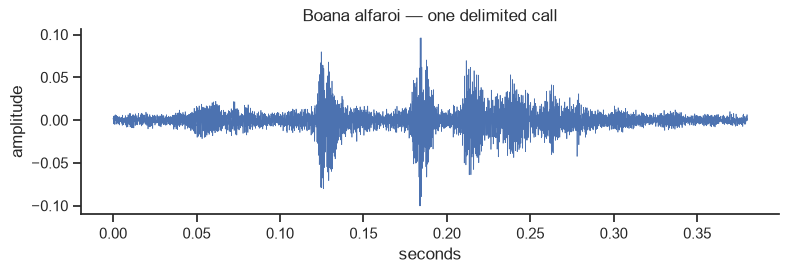

In [4]:
# Cut a single annotated call out of its recording and describe what came back.
def cut_call(row: pd.Series) -> tuple[np.ndarray, int]:
    """Read one annotated call out of its recording.

    Args:
        row (pandas.Series): A row of `annotated`, carrying wav, start and end.

    Returns:
        tuple[numpy.ndarray, int]: The samples of the call as float64 in [-1, 1], and the
            sample rate reported by the file itself rather than by the annotation.
    """
    audio, rate = sf.read(WAV_ON_DISK[row.wav.lower()],
                          start=row.start, stop=row.end, dtype="float64")
    return audio, rate

# Select the first annotated call whose WAV file is available and extract its audio segment.
example = annotated[annotated.on_disk].iloc[0]
call, rate = cut_call(example)

print("species        :", example.code, example.species)
print("recording      :", example.wav)
print("interval       :", example.start, "to", example.end, "samples")
print("samples read   :", len(call), "( expected", example.end - example.start, ")")
print("sample rate    :", rate, "Hz")
print("duration       :", round(len(call) / rate, 3), "s")
print("peak amplitude :", round(float(np.abs(call).max()), 4))

# Plot the waveform of the extracted call, with time in seconds on the x-axis.
figure, axis = plt.subplots(figsize=(9, 2.4))
axis.plot(np.arange(len(call)) / rate, call, linewidth=0.5)
axis.set(xlabel="seconds", ylabel="amplitude",
         title=f"{example.species} — one delimited call")
sns.despine()
plt.show()

`[OBSERVED]` The cut returns exactly the number of samples the interval asks for, at the rate the
file itself reports, and the waveform shows a call surrounded by very little else — the interval is
tight around the vocalisation rather than around a passage containing it.

`[INFERENCE]` This is the granularity the article's Table 1 counts, and it confirms what notebook 01
inferred from the annotation alone: the `.mat` intervals delimit individual calls, not sections.
Reading the range directly from the file means no recording is ever decoded in full.

## 4. Validating every cut

**What this section asks, and why it matters.** One successful cut proves the mechanism, not the
corpus. Every one of the 1461 calls has to come back before any of them becomes training material,
and this is the first point in the replication where that is possible: notebook 01 read headers and
annotations, never samples.

Notebook 01 already established that the boundaries are contained — no interval ends past the
duration its recording's header declares, across all 67 recordings whose audio is present. The
first check below asks the same question of a different source. There, containment was tested
against the duration the **header announces**; here it is tested against the samples `sf.read`
**actually returns**, which is not the same statement for a file whose header disagrees with its
data. It matters that the check is explicit, because `soundfile` does not raise when an interval
runs past the end of a file: it returns fewer samples than were asked for, and a shorter clip would
enter the feature matrix as if it were a whole call.

The remaining checks ask what a header cannot answer at all, and they do not all serve the same
purpose. A cut that is empty, or that falls short of the samples it asked for, is an **error**: it
would force a decision about the interval that produced it. Near-silence and clipping are not errors
but **properties of the material**, and they are measured here to describe the corpus rather than to
filter it. A replication does not get to discard recordings on quality grounds the article never
applied, so the outcome of those two checks is context, not a criterion: a species modelled in part
on distortion is a different claim from one modelled on timbre, and the difference can only be
stated if the amount was measured. The last check confronts the sample rate stored beside the
intervals with the one the file itself reports, since every conversion from samples to seconds in
this notebook depends on that agreement.

An empty count in this table is a result, not the absence of one.

In [5]:
# Read every annotated call and check the four ways a cut could be unusable.
SILENCE = 1e-4
CLIPPING = 0.999

records = []
for row in annotated[annotated.on_disk].itertuples():
    # Use `cut_rate` to avoid overwriting the `rate` variable from the example above.
    audio, cut_rate = sf.read(WAV_ON_DISK[row.wav.lower()],
                              start=row.start, stop=row.end, dtype="float64")
    if len(audio) > 0:
        peak = float(np.abs(audio).max()) # Calculate the maximum amplitude of the audio segment.
    else:
        peak = 0.0
    records.append({"code": row.code, "species": row.species, "wav": row.wav,
                    "rate": cut_rate, "samples": len(audio),
                    "expected": row.end - row.start,
                    "seconds": len(audio) / cut_rate, "peak": peak})

cuts = pd.DataFrame(records)

validation = pd.Series({
    "calls read": len(cuts),
    "fewer samples than requested": int((cuts.samples != cuts.expected).sum()),
    "empty": int((cuts.samples == 0).sum()),
    "near-silent (peak < 1e-4)": int((cuts.peak < SILENCE).sum()),
    "clipped (peak >= 0.999)": int((cuts.peak >= CLIPPING).sum()),
    "rate disagreeing with the annotation": int(
        (cuts.rate.values != annotated.loc[annotated.on_disk, "rate"].values).sum()),
}, name="occurrences")

print(validation.to_string())
print("\ntotal audio cut:", round(cuts.seconds.sum(), 2), "s")
print("peak amplitude: min", round(cuts.peak.min(), 4), " median", round(cuts.peak.median(), 4),
      " max", round(cuts.peak.max(), 4))
print("\nsample rates present:")
print(cuts.groupby("rate").agg(calls=("samples", "size"),
                               seconds=("seconds", "sum")).round(2).to_string())

clipped = cuts[cuts.peak >= CLIPPING]
if len(clipped):
    print("\ncalls reaching full scale:")
    print(clipped[["code", "species", "wav", "seconds", "peak"]].round(3).to_string(index=False))

calls read                              1461
fewer samples than requested               0
empty                                      0
near-silent (peak < 1e-4)                  0
clipped (peak >= 0.999)                    1
rate disagreeing with the annotation       0

total audio cut: 701.94 s
peak amplitude: min 0.0099  median 0.1983  max 1.0

sample rates present:
       calls  seconds
rate                 
44100    973   441.34
48000    488   260.60

calls reaching full scale:
code                     species                            wav  seconds  peak
 f04 Pristimantis conspicillatus LS100456 P. conspicillatus.WAV     0.46   1.0


`[OBSERVED]` All **1461** cuts return the requested number of samples, none is empty, none is
near-silent, and the rate reported by every file agrees with the rate stored beside its intervals.
Peak amplitude runs from **0.0099** to **1.0**, with a median of **0.1983**.

`[OBSERVED]` **One call reaches full scale**: 0.46 s of `f04` *Pristimantis conspicillatus*, taken
from `LS100456 P. conspicillatus.WAV`, with a peak of exactly 1.0.

`[OBSERVED]` The corpus is split across **two sample rates**, and both carry a substantial share:
**973 calls and 441.34 s at 44100 Hz**, **488 calls and 260.60 s at 48000 Hz**. This is the
condition the next section has to take a position on.

`[INFERENCE]` The clipped call is kept. The article says nothing about clipping, and it states that
it deliberately retained calls *"with background noise and some interference to study the
performance of the algorithm in the noisy conditions that occur in the study zone"*, so removing
material on quality grounds would be a departure from the procedure being replicated. It is one call
out of the 186 belonging to that species, and it is recorded here so that it can be found again if
`f04` behaves unexpectedly later.

`[INFERENCE]` No interval needs repairing and no cut needs excluding, so all 1461 calls enter the
pipeline as they are.

## 5. Sample rate: why no resampling step is introduced

**What this section asks, and why it matters.** The previous section showed the corpus mixes 44100
and 48000 Hz. Every pipeline that follows has to decide what to do about that, and the decision
changes the numbers, so it belongs in the open. This section contains
no code by design: it records a decision, and the decision is to add nothing.

Resampling everything to a single rate is defensible on methodological grounds. It removes a
variable from the comparison, guarantees that the framing produces the same number of samples per
frame for every call, and makes the mapping from DFT bins to filter-bank edges identical across the
corpus. If the goal were the best possible classifier, that is what this notebook would do.

The goal here is a replication, and the article does not resample. It states that its training
material was recorded at both rates and never mentions a resampling step, in the recording protocol,
in the segmentation, in the feature extraction, or in the experiments. It can afford that because
**its entire pipeline is specified in physical units rather than in samples**: frames of 20 ms,
overlap as a percentage, filter edges in Hz, a pre-emphasis coefficient that is dimensionless.

**Decision.** No resampling step is introduced in this replication. The mixed rates are carried
through, and every stage below is built per rate where the rate matters. Introducing one would be a
deviation from the article, so if it is ever added it will be as a separate, labelled experiment
whose effect on the results can be measured against this one, not as a change to the pipeline being
replicated.

## 6. Pre-emphasis

**What this section asks, and why it matters.** The first operation the article applies to a call is
a pre-emphasis filter:

> `[PAPER]` *Each frame was then pre-emphasised using the filter described by* H(Z) = 1 − 0.99 z⁻¹

It is a high-pass filter that boosts high frequencies relative to low ones. The reason it is
standard in cepstral analysis is that natural sound sources fall off in energy as frequency rises, so
without it the low-frequency bins dominate the spectrum and the coefficients describe little else.
The question this section asks is what it does to a real call from this corpus, since the answer
decides whether it is doing what it is supposed to.

samples in : 16758  samples out: 16758

share of spectral energy above 5000 Hz:
  before: 0.42 %
  after : 3.13 %


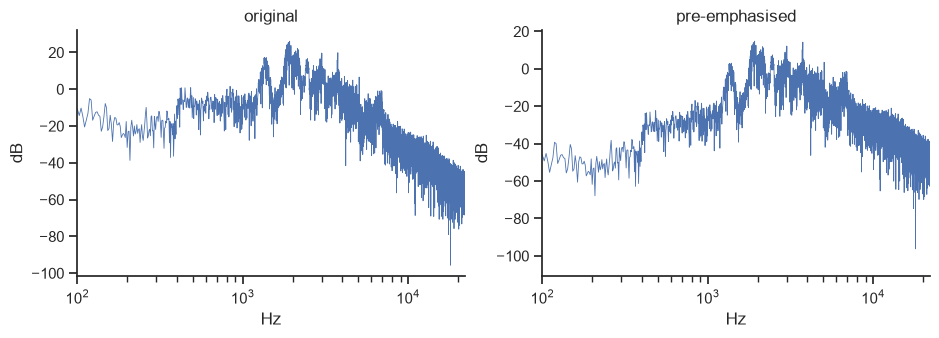

In [6]:
# Apply the article's pre-emphasis filter and compare the spectrum before and after.
PRE_EMPHASIS = 0.99


def pre_emphasise(signal: np.ndarray, coefficient: float = PRE_EMPHASIS) -> np.ndarray:
    """Apply H(z) = 1 - a*z^-1 to a signal.

    Args:
        signal (numpy.ndarray): One call, as samples.
        coefficient (float): The filter coefficient `a`, 0.99 in the article.

    Returns:
        numpy.ndarray: The filtered signal, the same length as the input. The first
            sample is kept as it is, since it has no predecessor to subtract.
    """
    # Keep the first sample unchanged and, from the second sample onward,
    # subtract a proportion of the previous sample.
    # This makes rapid changes in the signal more prominent.
    return np.append(signal[0], signal[1:] - coefficient * signal[:-1])

# Apply pre-emphasis to the example call extracted previously.
emphasised = pre_emphasise(call)

def share_above(signal: np.ndarray, hertz: float, sample_rate: int) -> float:
    """Fraction of a signal's spectral energy that sits above a frequency.

    Args:
        signal (numpy.ndarray): The samples to measure.
        hertz (float): The dividing frequency.
        sample_rate (int): Sample rate of the signal.

    Returns:
        float: Energy above `hertz` as a share of the total, between 0 and 1.
    """
    # Apply a Hamming window and compute the energy spectrum of the signal.
    spectrum = np.abs(np.fft.rfft(signal * np.hamming(len(signal)))) ** 2
    # Obtain the frequencies associated with each spectral value and identify
    # the frequencies above the selected threshold.
    above = np.fft.rfftfreq(len(signal), 1 / sample_rate) > hertz

    # Calculate the fraction of spectral energy above the threshold.
    return float(spectrum[above].sum() / spectrum.sum())


print("samples in :", len(call), " samples out:", len(emphasised))
print("\nshare of spectral energy above 5000 Hz:")
print("  before:", round(share_above(call, 5000, rate) * 100, 2), "%")
print("  after :", round(share_above(emphasised, 5000, rate) * 100, 2), "%")

figure, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for axis, signal, title in zip(axes, (call, emphasised), ("original", "pre-emphasised")):
    spectrum = np.abs(np.fft.rfft(signal * np.hamming(len(signal))))
    frequencies = np.fft.rfftfreq(len(signal), 1 / rate)
    axis.semilogx(frequencies[1:], 20 * np.log10(spectrum[1:] + 1e-12), linewidth=0.6)
    axis.set(xlabel="Hz", ylabel="dB", title=title, xlim=(100, rate / 2))
sns.despine()
plt.show()

`[OBSERVED]` The filter keeps the signal length unchanged: the input and output both contain 
**16758 samples**. It also tilts the spectrum as intended: the share of spectral energy above 
5000 Hz rises from **0.42%** to **3.13%**, a factor of about seven. This confirms that the filter is performing its intended role before feature 
extraction. 

`[INFERENCE]` The increase in high-frequency energy does not mean that the filter creates new 
high-frequency information. Instead, pre-emphasis reduces the relative dominance of low 
frequencies, changing the balance that later stages of the pipeline will analyse.



## 7. Framing, overlap and the Hamming window

**What this section asks, and why it matters.** A call lasts anywhere from a fifth of a second to
several seconds, and a classifier needs observations of fixed size. The article cuts each call into
short frames and describes one vector per frame, which is how a variable-length call becomes a
variable *number* of fixed-size observations:

> `[PAPER]` *Fragments of sound containing frog-calls resulting from the segmentation step (…) were
> divided into 20 ms frames with 75% overlap.*

> `[PAPER]` *and Hamming-windowed to minimize discontinuities on the edges.*

Two things have to be settled before that can be implemented.

The first is arithmetic. The frame length and the hop have to be converted from milliseconds into
samples, and at 44100 Hz a 5 ms hop is not a whole number of samples, so it has to be rounded.

The second is that the article states the same quantity twice, but the two descriptions do not appear
to correspond to the same frame rate.. The
passage above, from section 3.4, specifies 20 ms frames with 75% overlap: a frame every 5 ms, and
therefore about 200 feature vectors per second of call. Section 4.1, describing the experiments,
reports models

> `[PAPER]` *trained using 6, 12 and 18 seconds of frog-call corresponding to 600, 1200 and 12800
> 12-dimensional mel-cepstral feature vectors.*

600 vectors for 6 seconds, and 1200 for 12, both come to 100 vectors per second — a 10 ms hop and
50% overlap, half of what section 3.4 specifies. The third figure, 12800 for 18 seconds, agrees with
neither and appears to be an error for 1800.

This section implements section 3.4, because that is the passage that specifies the extraction
algorithm, and reports the frame counts that come out of it.

,rate,frame_samples,hop_samples,exact_hop_samples,frames_per_second
0,44100,882,220,220.5,200.45
1,48000,960,240,240.0,200.00


call duration : 0.38 s
frames        : 73 of 882 samples each


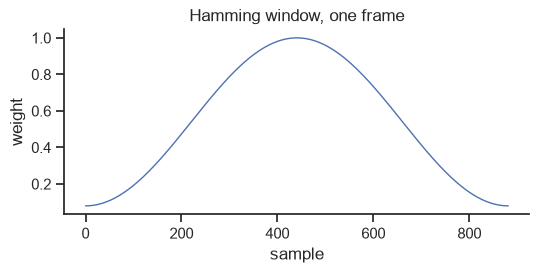

In [7]:
# Convert the article's frame geometry into samples, at both rates, and frame one call.
FRAME_SECONDS = 0.020
OVERLAP = 0.75


def frame_geometry(rate: int) -> tuple[int, int]:
    """Frame length and hop in samples for one sample rate.

    Args:
        rate (int): Samples per second.

    Returns:
        tuple[int, int]: Frame length and hop, both rounded to whole samples.
    """
    length = int(round(FRAME_SECONDS * rate))
    hop = int(round(FRAME_SECONDS * (1 - OVERLAP) * rate))
    return length, hop


def frame_signal(signal: np.ndarray, rate: int) -> np.ndarray:
    """Cut a signal into overlapping Hamming-windowed frames.

    Args:
        signal (numpy.ndarray): One call, already pre-emphasised.
        rate (int): Sample rate of that call.

    Returns:
        numpy.ndarray: Shape (frames, length). Empty when the call is shorter than one
            frame, so that a caller sees no frames rather than a padded invention.
    """
    length, hop = frame_geometry(rate)
    if len(signal) < length:
        return np.empty((0, length))
    return sliding_window_view(signal, length)[::hop] * np.hamming(length)


# The geometry at both rates side by side. The unrounded hop is kept as a column because
# it is the one place where the two rates stop dividing evenly.
geometry = pd.DataFrame(
    [{"rate": rate, "frame_samples": frame_geometry(rate)[0],
      "hop_samples": frame_geometry(rate)[1],
      "exact_hop_samples": FRAME_SECONDS * (1 - OVERLAP) * rate,
      "frames_per_second": rate / frame_geometry(rate)[1]}
     for rate in sorted(cuts.rate.unique())])
display(geometry.round(2))

# Frame the example call, taking the pre-emphasised version produced in section 6.
frames = frame_signal(emphasised, rate)
print("call duration :", round(len(call) / rate, 3), "s")
print("frames        :", frames.shape[0], "of", frames.shape[1], "samples each")

# The window itself: the taper that suppresses the discontinuity at each end of a frame.
figure, axis = plt.subplots(figsize=(6, 2.4))
axis.plot(np.hamming(frame_geometry(rate)[0]), linewidth=1)
axis.set(xlabel="sample", ylabel="weight", title="Hamming window, one frame")
sns.despine()
plt.show()

`[OBSERVED]` A 20 ms frame is **882 samples at 44100 Hz and 960 at 48000 Hz**. The 5 ms hop is 240
samples at 48000 Hz but **220.5 at 44100 Hz**, which is not a whole number and is rounded to 220.

`[OBSERVED]` The geometry yields **200.45 frames per second at 44100 Hz and 200.00 at 48000 Hz** —
the rate section 3.4 implies, and twice the 100 per second that the vector counts of section 4.1
imply.

`[INFERENCE]` The frame configuration described in section 3.4 and the number of feature vectors
reported in section 4.1 do not appear to correspond to the same frame rate. Section 3.4 specifies
the extraction procedure, with 20 ms frames and 75% overlap, so this configuration is followed here.
The resulting number of frames is therefore reported as obtained from this implementation rather
than adjusted to match the vector counts mentioned in section 4.1. This keeps the replication
faithful to the described extraction algorithm while documenting the difference between the two
parts of the article.

## 8. From frame to spectrum: the DFT

What this section asks, and why it matters. So far, each frame is represented as a signal in the time domain (how the amplitude changes from one sample to the next). The DFT transforms this information to show which frequencies make up the sound and how much each one contributes. This representation is necessary because the model does not work directly with the audio samples, but rather with features based on the spectral content of the sound.

> `[PAPER]` *The discrete Fourier transform (DFT) was taken and the triangular-shaped 40-element
> filterbank of Figure 6(b) was applied.*

The article does not state the transform size. That is a free parameter, and it has to be fixed
here. A frame is 882 or 960 samples depending on the rate, and the natural choice is the next power
of two above both, so that the same transform size serves the whole corpus and the two rates differ
only in how many hertz each bin covers.

,rate,n_fft,bins,hz_per_bin,nyquist_hz
0,44100,1024,513,43.07,22050
1,48000,1024,513,46.88,24000


frames in : (73, 882)  power spectra out: (73, 513)


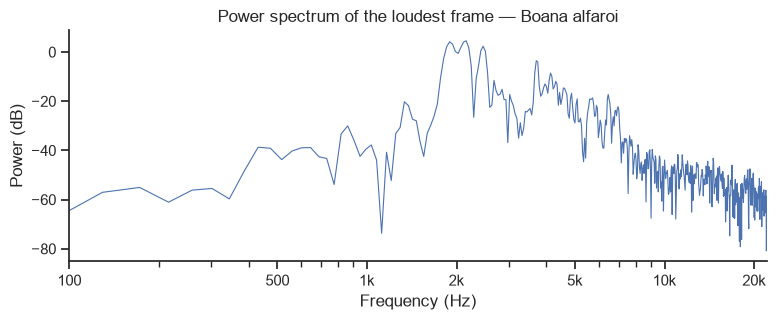

In [8]:
# Transform the frames of one call and show the resulting spectrum.
N_FFT = 1024


def frame_power(frames: np.ndarray, n_fft: int = N_FFT) -> np.ndarray:
    """Power spectrum of every frame.

    Args:
        frames (numpy.ndarray): Shape (frames, length), already windowed.
        n_fft (int): Transform size. Frames shorter than this are zero-padded.

    Returns:
        numpy.ndarray: Shape (frames, n_fft // 2 + 1), the squared magnitude of the DFT.
    """
    return np.abs(np.fft.rfft(frames, n=n_fft)) ** 2


power = frame_power(frames)
bin_width = pd.DataFrame([{"rate": r, "n_fft": N_FFT, "bins": N_FFT // 2 + 1,
                           "hz_per_bin": round(r / N_FFT, 2), "nyquist_hz": r // 2}
                          for r in sorted(cuts.rate.unique())])
display(bin_width)

print("frames in :", frames.shape, " power spectra out:", power.shape)

# The frame carrying the most spectral energy, as the clearest single example of what a
# call looks like in the frequency domain.
loudest = int(power.sum(axis=1).argmax())

frequencies = np.fft.rfftfreq(N_FFT, 1 / rate)
spectrum_db = 10 * np.log10(power[loudest] + 1e-12)

figure, axis = plt.subplots(figsize=(9, 3))
axis.semilogx(frequencies, spectrum_db, linewidth=0.8)
axis.set(xlabel="Frequency (Hz)", ylabel="Power (dB)", xlim=(100, rate / 2),
         title=f"Power spectrum of the loudest frame — {example.species}")

# A logarithmic axis labels its ticks as powers of ten, which does not read against the
# frequency ranges Table 1 states in hertz.
axis.set_xticks([100, 500, 1000, 2000, 5000, 10000, 20000],
                ["100", "500", "1k", "2k", "5k", "10k", "20k"])

sns.despine()
plt.show()

`[OBSERVED]` A transform size of 1024 covers both frame lengths and gives 513 bins, each
43.07 Hz wide at 44100 Hz and 46.88 Hz at 48000 Hz.

`[INFERENCE]` The transform size is a choice made in this replication because the article does not
specify it. Using the smallest power of two that contains both frame lengths keeps the same
transformation size across the corpus while minimizing zero-padding.

`[OBSERVED]` The Nyquist limits of 22050 Hz and 24000 Hz are well above the 430–7500 Hz range where frog-call energy is mainly concentrated, so the recordings cover the relevant frequency content of the studied species.

## 9. The modified filter bank

**What this section asks, and why it matters.** This is the contribution of the article and the part
of it that is specified least. The authors argue that the mel scale is built for human hearing and is
therefore the wrong distribution for frog calls, and they replace it:

> `[PAPER]` *We propose using hand-crafted cepstral coefficients with a modified filter-bank
> distribution following the layout shown in Figure 6 for frog-call recognition.*

What the article provides is a picture. Figure 6(a) shows a standard mel-scale bank spanning roughly
100 Hz to 20 kHz; Figure 6(b) shows the modified bank, with the same triangular shape and the same
upper limit but its lowest filter starting near 500 Hz. There is no table of cut-off frequencies, no
formula, and no statement of the spacing rule. **The bank implemented here is therefore an estimate
read off that figure**, and it is the largest source of deviation in this notebook.

The estimate keeps everything that is stated — 40 triangular filters, an upper edge at 20 kHz — and
takes the lower edge as 500 Hz from the figure. The spacing between the two edges follows the mel
layout of Figure 6(a), because that is the distribution the modified bank is drawn as a variation
of.

filters: 40  lower edge: 500 Hz  upper edge: 20000 Hz
first three filter centres: [586.3 678.8 778. ] Hz
last three filter centres : [16106.4 17315.2 18611. ] Hz
filters with centre below 7500 Hz, where Table 1 places the call energy: 27 of 40

empty filters (no DFT bin falls inside them):
  44100 Hz: 0
  48000 Hz: 0


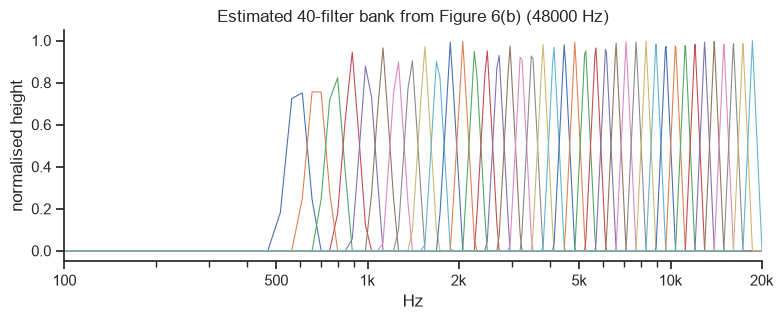

In [9]:
# Build the 40-filter bank estimated from Figure 6(b) of the article.
# The paper specifies the number of filters and frequency limits, but not the exact cutoff
# frequencies, so the distribution is reconstructed using the Mel spacing shown in Figure 6(a).
N_FILTERS = 40
LOW_HZ = 500
HIGH_HZ = 20000


def filter_bank(rate: int, n_filters: int = N_FILTERS, n_fft: int = N_FFT,
                low_hz: float = LOW_HZ, high_hz: float = HIGH_HZ) -> np.ndarray:
    """Triangular filter bank laid out between two edges, mapped onto the DFT bins.

    Args:
        rate (int): Sample rate of the audio the bank will be applied to.
        n_filters (int): Number of triangular filters.
        n_fft (int): Transform size the bins come from.
        low_hz (float): Lower edge of the lowest filter.
        high_hz (float): Upper edge of the highest filter.

    Returns:
        numpy.ndarray: Shape (n_filters, n_fft // 2 + 1), one row per filter.
    """
    # htk=True selects the 2595*log10(1 + f/700) mel formula, which is the layout Figure 6(a)
    # is drawn with. The default in librosa is Slaney's variant, which would space the filters
    # differently.
    # norm=None leaves every triangle at unit height, matching the "Normalized Height" axis of
    # Figure 6 instead of normalising each filter by its area.
    return librosa.filters.mel(sr=rate, n_fft=n_fft, n_mels=n_filters,
                               fmin=low_hz, fmax=high_hz, norm=None, htk=True)


# Build one filter bank for each sample rate present in the corpus.
# The frequency bins differ slightly between rates, so the mapping from Hz to DFT bins
# must be performed separately for each recording configuration.
BANKS = {rate: filter_bank(rate) for rate in sorted(cuts.rate.unique())}


# Inspect the estimated filter locations in Hertz.
# These values are useful for checking that the implemented bank follows the intended range.
edges_hz = librosa.mel_frequencies(n_mels=N_FILTERS + 2, fmin=LOW_HZ, fmax=HIGH_HZ,
                                   htk=True)

print("filters:", N_FILTERS, " lower edge:", LOW_HZ, "Hz  upper edge:", HIGH_HZ, "Hz")
print("first three filter centres:", np.round(edges_hz[1:4], 1), "Hz")
print("last three filter centres :", np.round(edges_hz[-4:-1], 1), "Hz")

# Check how many filters are centred below 7500 Hz, the approximate upper range where
# the article reports most frog-call energy.
print("filters with centre below 7500 Hz, where Table 1 places the call energy:",
      int((edges_hz[1:-1] < 7500).sum()), "of", N_FILTERS)


# Verify that every filter contains at least one DFT bin for each sample rate.
# An empty filter would indicate that the frequency resolution is too coarse for that band.
print("\nempty filters (no DFT bin falls inside them):")
for rate, bank in BANKS.items():
    print(f"  {rate} Hz: {int((bank.sum(axis=1) == 0).sum())}")


# Visualise the triangular filters for one sample rate.
# Each curve represents the frequency region and weighting of one filter.
figure, axis = plt.subplots(figsize=(9, 3))
frequencies = np.fft.rfftfreq(N_FFT, 1 / 48000)

for row in BANKS[48000]:
    axis.semilogx(frequencies, row, linewidth=0.8)

axis.set(
    xlabel="Hz",
    ylabel="normalised height",
    xlim=(100, 20000),
    title="Estimated 40-filter bank from Figure 6(b) (48000 Hz)"
)

# A logarithmic axis labels its ticks as powers of ten, which does not read against the
# frequency ranges Table 1 states in hertz.
axis.set_xticks([100, 500, 1000, 2000, 5000, 10000, 20000],
                ["100", "500", "1k", "2k", "5k", "10k", "20k"])

sns.despine()
plt.show()

`[OBSERVED]` The estimated bank spans from **500 Hz to 20000 Hz** using 40 triangular filters. The
filter layout follows the structure shown in Figure 6(b): filters are narrower at lower frequencies
and progressively wider towards the upper end of the spectrum. The first filter centre is at
**586.3 Hz** and the last at **18611.0 Hz**.

`[OBSERVED]` No filter is empty at either sample rate: each of the 40 filters contains at least one
DFT bin, so all filter energies are defined for every frame in the corpus.

`[INFERENCE]` The article does not specify the method used to construct the modified filter-bank distribution. It only provides the final layout in Figure 6(b), leaving multiple possible reconstruction strategies. For this initial replication, the filter spacing is approximated using a Mel-based distribution within the frequency range estimated from the figure. This should not be interpreted as assuming that frog calls follow human auditory perception; rather, it is a practical approximation due to missing implementation details. However, this choice may partially reintroduce assumptions from the standard Mel scale that the authors intended to modify, so the filter-bank design will be revisited after clarification from the original authors. Until this implementation detail is clarified with the authors, a standard Mel filter-bank implementation is used as a temporary baseline. This component will be replaced once the original filter design is confirmed

## 10. Log energies, DCT and the cepstral coefficients

**What this section asks, and why it matters.** The last two operations turn 40 filter energies into
the 20 numbers that describe a frame:

> `[PAPER]` *The log of the energy of each filter was obtained and the discrete cosine transform
> (DCT) of the resultant vector of log-energies calculated to decorrelate the energies. Finally, the
> 20 first elements of the resultant vector were concatenated per each frame and the resultant
> matrix used as feature set for the classification step.*

The logarithm compresses a range that spans several orders of magnitude into one a Gaussian can
model. The DCT decorrelates the neighbouring filter energies, which overlap by construction and are
therefore strongly correlated — and that matters directly here, because the article models each
species with a GMM using **diagonal** covariance matrices, which assume the dimensions are
independent.

frames                 : (73, 882)
filter energies        : (73, 40)
cepstral coefficients  : (73, 20)

filter energies of the loudest frame, before and after the log:
  raw   min 9.190e-05  max 7.610e+00
  log   min -9.29  max 2.03

mean absolute correlation between dimensions, on this call's 73 frames:
  log filter energies, first 20: 0.331
  cepstral coefficients       : 0.394


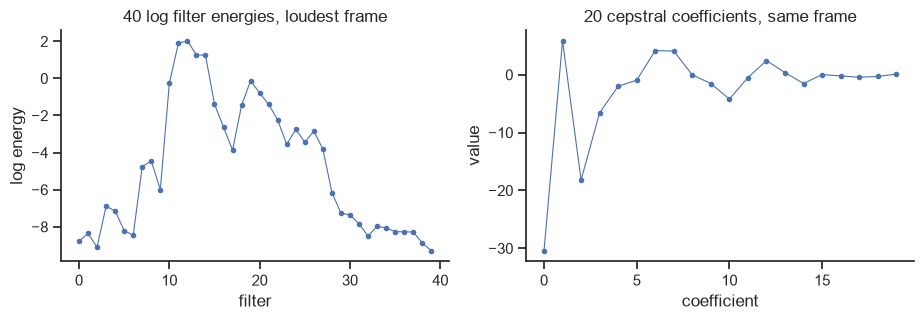

In [10]:
# Turn one call's frames into cepstral coefficients, and show each stage.
N_COEFFICIENTS = 20


def cepstral_coefficients(frames: np.ndarray, rate: int,
                          n_coefficients: int = N_COEFFICIENTS) -> np.ndarray:
    """Filter-bank log-energies decorrelated by a DCT, truncated to the first elements.

    Args:
        frames (numpy.ndarray): Windowed frames, shape (frames, length).
        rate (int): Sample rate, which selects the filter bank.
        n_coefficients (int): How many of the DCT outputs to keep.

    Returns:
        numpy.ndarray: Shape (frames, n_coefficients).
    """
    # Each filter integrates the power falling inside its triangle: (frames, bins)
    # multiplied by (bins, filters) leaves one energy per filter per frame.
    energies = frame_power(frames) @ BANKS[rate].T
    # eps keeps the logarithm finite where a filter catches no energy at all.
    log_energies = np.log(energies + np.finfo(float).eps)
    return dct(log_energies, type=2, axis=1, norm="ortho")[:, :n_coefficients]


# The same two stages recomputed outside the function, so the intermediate values can be
# printed and plotted below.
energies = power @ BANKS[rate].T
log_energies = np.log(energies + np.finfo(float).eps)
coefficients = cepstral_coefficients(frames, rate)

print("frames                 :", frames.shape)
print("filter energies        :", energies.shape)
print("cepstral coefficients  :", coefficients.shape)
print("\nfilter energies of the loudest frame, before and after the log:")
print("  raw   min", f"{energies[loudest].min():.3e}", " max", f"{energies[loudest].max():.3e}")
print("  log   min", round(float(log_energies[loudest].min()), 2),
      " max", round(float(log_energies[loudest].max()), 2))

# Whether the DCT decorrelates. Both sides are measured on the same number of dimensions,
# so the filter energies are truncated to the first 20 as well.
correlation_before = np.corrcoef(log_energies.T)
correlation_after = np.corrcoef(coefficients.T)
off_diagonal = ~np.eye(N_COEFFICIENTS, dtype=bool)
print("\nmean absolute correlation between dimensions, on this call's",
      len(frames), "frames:")
print("  log filter energies, first 20:",
      round(float(np.abs(correlation_before[:N_COEFFICIENTS, :N_COEFFICIENTS][off_diagonal]).mean()), 3))
print("  cepstral coefficients       :",
      round(float(np.abs(correlation_after[off_diagonal]).mean()), 3))

figure, axes = plt.subplots(1, 2, figsize=(11, 3), width_ratios=[1, 1])
axes[0].plot(log_energies[loudest], marker="o", markersize=3, linewidth=0.8)
axes[0].set(xlabel="filter", ylabel="log energy", title="40 log filter energies, loudest frame")
axes[1].plot(coefficients[loudest], marker="o", markersize=3, linewidth=0.8)
axes[1].set(xlabel="coefficient", ylabel="value", title="20 cepstral coefficients, same frame")
sns.despine()
plt.show()

`[OBSERVED]`The transformation reduces each frame from 40 filter-bank energies to the 20 cepstral
coefficients used by the article. The logarithm compresses the large dynamic range of filter
energies, reducing values from approximately 10^-4–10^1 to a narrower range.

`[OBSERVED]`The DCT produces a compact representation of the log filter energies, where the first
20 coefficients are retained as the final feature vector for classification.

`[INFERENCE]` The article applies the DCT to decorrelate filter energies before fitting diagonal
covariance GMMs. In this single-call example, the measured correlation reduction is not evident,
likely because the estimate is based on only 73 frames and does not represent the full dataset
distribution.

`[INFERENCE]` Using a high-level MFCC function would combine the filter bank, logarithm, and DCT steps into a single operation, which would reduce control over the feature extraction pipeline. Since the filter bank is the main uncertain component in this replication and may need to be modified after clarification from the original authors, these stages are kept separate so that the filter-bank implementation can be replaced without changing the subsequent transformations.

### Does the correlation decrease across other calls?

The previous measurement did not show the expected reduction in correlation, and a single call is not sufficient to draw conclusions. The same analysis is repeated here on calls with different durations, selected by duration percentiles to cover a wider range of frame counts rather than relying on a few arbitrary examples.

In [11]:
# Check whether the correlation reduction observed after DCT appears consistently across
# multiple calls. This is an exploratory analysis to determine whether the previous result
# was specific to a single example or represents a more general behaviour of the feature
# extraction pipeline.


def correlation_change(row: pd.Series) -> tuple[float, float]:
    """Calculate the mean absolute correlation between feature dimensions before and after DCT.

    The comparison is performed on the first 20 log filter-bank energies and the resulting
    20 cepstral coefficients, matching the dimensionality used as the final feature vector
    for classification.

    Args:
        row (pandas.Series): A call annotation containing the audio file and segment limits.

    Returns:
        tuple[float, float]: Mean absolute correlation before and after applying the DCT.
    """

    # Load the segmented frog call corresponding to the annotation.
    audio, rate = sf.read(
        WAV_ON_DISK[row.wav.lower()],
        start=row.start,
        stop=row.end,
        dtype="float64"
    )

    # Apply the same preprocessing pipeline used for feature extraction:
    # pre-emphasis followed by framing and windowing.
    frames = frame_signal(pre_emphasise(audio), rate)

    # Compute log filter-bank energies. These represent the features before the DCT step,
    # where neighbouring filters are expected to be correlated due to their overlap.
    log_energies = np.log(
        frame_power(frames) @ BANKS[rate].T + np.finfo(float).eps
    )

    # Compute the cepstral coefficients obtained after applying the DCT.
    # These are the final decorrelated features used by the classifier.
    coefficients = cepstral_coefficients(frames, rate)

    # Measure the average absolute correlation between feature dimensions before DCT.
    # Only the first 20 filter energies are used to match the number of retained coefficients.
    before = np.abs(
        np.corrcoef(log_energies[:, :N_COEFFICIENTS].T)
        [off_diagonal]
    ).mean()

    # Measure the average absolute correlation between cepstral coefficients after DCT.
    after = np.abs(
        np.corrcoef(coefficients.T)
        [off_diagonal]
    ).mean()

    return before, after


# Select a small reproducible sample of calls from the available dataset.
# The fixed seed ensures that the same calls are selected in future executions.
sample = annotated[annotated.on_disk].sample(
    15,
    random_state=SEED
)

results = []

for row in sample.itertuples():

    # Compare the average correlation before and after the DCT transformation.
    before, after = correlation_change(row)

    results.append({
        "species": row.code,
        "before_dct": round(float(before), 3),
        "after_dct": round(float(after), 3),

        # Indicates whether the correlation decreased for this specific call.
        "decreased": after < before
    })


correlation_results = pd.DataFrame(results)

display(correlation_results)


# Summarise whether the expected decorrelation effect appears across the sampled calls.
print(
    "Calls where correlation decreased:",
    correlation_results.decreased.sum(),
    "of",
    len(correlation_results)
)

print(
    "Mean correlation before:",
    round(correlation_results.before_dct.mean(), 3)
)

print(
    "Mean correlation after:",
    round(correlation_results.after_dct.mean(), 3)
)

,species,before_dct,after_dct,decreased
0,f02,0.622,0.374,True
1,f06,0.747,0.389,True
2,f10,0.543,0.380,True
3,f10,0.630,0.389,True
4,f05,0.312,0.442,False
5,f03,0.669,0.449,True
6,f07,0.411,0.328,True
7,f10,0.704,0.379,True
8,f05,0.395,0.390,True
9,f08,0.620,0.326,True


Calls where correlation decreased: 14 of 15
Mean correlation before: 0.55
Mean correlation after: 0.387


`[OBSERVED]` Across 15 sampled calls, the mean absolute correlation decreased from 0.550 in the
log filter energies to 0.387 after the DCT. The correlation decreased in 14 out of 15 calls,
suggesting that the decorrelation effect expected from the DCT is generally observed across
different recordings.

## 11. The feature matrix and the labels

**What this section asks, and why it matters.** Everything so far has run on one call. Applying the
same chain to all 1461 of them produces the two objects a classifier needs: a matrix in which every
row is one frame described by 20 numbers, and a label vector saying which species produced each row.

The identity of the call and of the recording each frame came from is carried alongside. It is not
part of the features, and no model will see it, but without it a split cannot be grouped by
recording later, and a frame cannot be traced back to the audio it came from.

In [12]:
# Run the whole chain over every call and assemble the feature matrix and the labels.
# Sections 6 to 10 applied end to end, one call at a time: no recording is ever held in
# memory in full, only the call being processed.
blocks, rows = [], []
for row in annotated[annotated.on_disk].itertuples():
    audio, call_rate = sf.read(WAV_ON_DISK[row.wav.lower()],
                               start=row.start, stop=row.end, dtype="float64")
    call_frames = frame_signal(pre_emphasise(audio), call_rate)
    if not len(call_frames):
        continue
    blocks.append(cepstral_coefficients(call_frames, call_rate))
    rows.append({"code": row.code, "species": row.species, "wav": row.wav,
                 "recording": row.recording, "rate": call_rate,
                 "seconds": len(audio) / call_rate, "frames": len(call_frames),
                 "start": int(row.start), "end": int(row.end)})

per_call = pd.DataFrame(rows)
X = np.vstack(blocks)
# One row per frame, repeating each call's identity as many times as it produced frames,
# so every row of X can be traced back to the recording it came from.
frame_index = per_call.loc[per_call.index.repeat(per_call.frames)].reset_index(drop=True)
y = frame_index.code.to_numpy()

print("calls that produced frames:", len(per_call), "of", int(annotated.on_disk.sum()))
print("X:", X.shape, " y:", y.shape)
print("frames per second of audio:", round(len(X) / per_call.seconds.sum(), 1))
print("X dtype:", X.dtype, " memory:", round(X.nbytes / 1e6, 1), "MB\n")

# The decorrelation the DCT is there for, measured on the whole corpus rather than on
# the frames of a single call.
all_log_energies = []
for row in annotated[annotated.on_disk].sample(200, random_state=SEED).itertuples():
    audio, call_rate = sf.read(WAV_ON_DISK[row.wav.lower()],
                               start=row.start, stop=row.end, dtype="float64")
    sample_frames = frame_signal(pre_emphasise(audio), call_rate)
    if len(sample_frames):
        all_log_energies.append(
            np.log(frame_power(sample_frames) @ BANKS[call_rate].T + np.finfo(float).eps))

sampled_energies = np.vstack(all_log_energies)
sampled_coefficients = dct(sampled_energies, type=2, axis=1, norm="ortho")[:, :N_COEFFICIENTS]
off = ~np.eye(N_COEFFICIENTS, dtype=bool)

print("\nmean absolute correlation across", len(sampled_energies),
      "frames drawn from 200 calls:")
print("  log filter energies, first 20:",
      round(float(np.abs(np.corrcoef(sampled_energies[:, :N_COEFFICIENTS].T)[off]).mean()), 3))
print("  cepstral coefficients       :",
      round(float(np.abs(np.corrcoef(sampled_coefficients.T)[off]).mean()), 3))

per_species = (per_call.groupby(["code", "species"])
               .agg(calls=("frames", "size"), seconds=("seconds", "sum"),
                    frames=("frames", "sum")).round(2))
per_species["share_of_frames"] = (per_species.frames / per_species.frames.sum() * 100).round(1)
# A totals row, so the size of the corpus can be read off the same table as the split
# between species. The share is set to 100 rather than summed, because the per-species
# shares are already rounded and would not add up exactly.
corpus_total = pd.DataFrame(
    [{"calls": per_species.calls.sum(), "seconds": per_species.seconds.sum(),
      "frames": per_species.frames.sum(), "share_of_frames": 100.0}],
    index=pd.MultiIndex.from_tuples([("TOTAL", "")], names=per_species.index.names))

with_total = pd.concat([per_species, corpus_total]).round(2)
with_total[["calls", "frames"]] = with_total[["calls", "frames"]].astype(int)
display(with_total)

calls that produced frames: 1461 of 1461
X: (136005, 20)  y: (136005,)
frames per second of audio: 193.8
X dtype: float64  memory: 21.8 MB




mean absolute correlation across 18924 frames drawn from 200 calls:
  log filter energies, first 20: 0.574
  cepstral coefficients       : 0.173


,,calls,seconds,frames,share_of_frames
code,species,,,,
f01,Boana alfaroi,98,44.72,8650,6.4
f02,Dendropsophus bifurcus,99,41.72,8047,5.9
f03,Boana cinerascens,169,102.58,20009,14.7
f04,Pristimantis conspicillatus,186,77.94,15030,11.1
f05,Leptodactylus discodactylus,340,114.36,21852,16.1
f06,Osteocephalus fuscifacies,54,24.94,4826,3.5
f07,Boana lanciformis,101,57.84,11265,8.3
f08,Rhinella margaritifera,96,102.66,20244,14.9
f09,Dendropsophus parviceps,2,1.18,230,0.2


`[OBSERVED]` The complete feature extraction pipeline produced 136005 frame-level feature vectors
with 20 cepstral dimensions from 1461 calls. No available call failed to produce valid frames.

`[OBSERVED]` The DCT reduced the mean absolute correlation between feature dimensions from 0.574
in the log filter energies to 0.173 in the cepstral coefficients, supporting its role in reducing
redundancy before fitting diagonal-covariance GMMs.

`[OBSERVED]` The classes are unbalanced. Among the nine species with usable material the share of
frames runs from **3.5%** (`f06`) to **19.0%** (`f10`), and `f09` contributes **0.2%**. This reflects the limited availability of that species in the recovered annotations rather than a preprocessing issue.

## 12. What this notebook hands over

**What this section asks, and why it matters.** Everything built above lives in memory and
disappears with the kernel. The notebook that trains the models needs the features, the labels, and
enough information to trace every row back to the audio it came from — and recomputing the chain
over 1461 calls each time that notebook opens is time spent for nothing.

The matrix and the labels carry one row per frame, in the same order. The call table carries one row
per call, and the frames follow that order too: the first call contributes the first `frames` rows
of the matrix, the second the next, and so on. That correspondence is what lets a later step group
frames by call or by recording without opening a single audio file again. `data/` is not tracked by
git, so none of this is committed.

In [13]:
# Write what the next notebook needs, so it can start from the features instead of running
# the whole chain again. `data/` is outside version control.
PROCESSED_DIR = Path("..") / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

np.save(PROCESSED_DIR / "features.npy", X)
np.save(PROCESSED_DIR / "labels.npy", y.astype("U"))
per_call.to_csv(PROCESSED_DIR / "calls.csv", index=False)

# Read the files back and compare them against what is in memory. A stored artefact that
# does not reload into the same arrays is worse than no artefact at all.
reloaded_features = np.load(PROCESSED_DIR / "features.npy")
reloaded_labels = np.load(PROCESSED_DIR / "labels.npy")
reloaded_calls = pd.read_csv(PROCESSED_DIR / "calls.csv")

print("features.npy:", reloaded_features.shape,
      " identical to X:", np.array_equal(reloaded_features, X))
print("labels.npy  :", reloaded_labels.shape,
      " identical to y:", np.array_equal(reloaded_labels, y.astype("U")))
print("calls.csv   :", reloaded_calls.shape,
      " frames add up to the matrix:", int(reloaded_calls.frames.sum()) == len(reloaded_features))

print("\nwritten to", PROCESSED_DIR.as_posix())
# Only the three files this notebook writes: the folder also holds what later notebooks
# produce, and listing those here would make this output depend on them.
for name in ("calls.csv", "features.npy", "labels.npy"):
    path = PROCESSED_DIR / name
    print(f"  {path.name:<14} {path.stat().st_size / 1e6:>6.1f} MB")

features.npy: (136005, 20)  identical to X: True
labels.npy  : (136005,)  identical to y: True
calls.csv   : (1461, 9)  frames add up to the matrix: True

written to ../data/processed
  calls.csv         0.1 MB
  features.npy     21.8 MB
  labels.npy        1.6 MB


`[OBSERVED]` The processed artifacts were successfully written and reloaded without changes.
The feature matrix contains 136005 frame-level vectors with 20 cepstral coefficients, aligned
with their species labels and call-level metadata.

`[OBSERVED]` The sum of frames stored in the call table matches the number of rows in the feature
matrix, confirming that the correspondence between calls, frames, and labels was preserved.

## 13. Conclusions and limitations

**What this notebook delivers.** A feature matrix of 136005 rows and 20 columns, one row per 20 ms
frame, built from the 1461 annotated calls whose audio was delivered; a label per row naming the
species; and a table of the 1461 calls carrying the recording, the sample rate and the duration each
one came from. Together they are the input the article's classifier expects, and they are written to
`data/processed` so that the modelling step does not repeat the work.

**What was implemented.** The article's front end, stage by stage and in the order it describes it:
pre-emphasis, 20 ms frames at 75% overlap, a Hamming window, a discrete Fourier transform, a
40-filter triangular bank, the logarithm of each filter energy, and a discrete cosine transform
truncated to 20 coefficients. Each stage was shown on a real call before being applied to the whole
corpus, and the decorrelation the cosine transform exists for was measured rather than assumed.

**Decisions taken here, which the article does not state.**

1. **No resampling.** The corpus is carried through at both rates, as argued in section 5. The
   consequences are visible in two places: the 5 ms hop rounds to 220 samples at 44100 Hz instead of
   220.5, and a DFT bin covers 43.07 Hz at one rate and 46.88 Hz at the other.
2. **A transform size of 1024**, the smallest power of two that holds a 20 ms frame at both rates.
   The article does not state one.
3. **A filter bank estimated from Figure 6(b)**: 40 triangular filters between 500 Hz and 20 kHz,
   spaced on the mel layout the figure is drawn against, built with `librosa` so that every
   assumption is a named argument.
4. **Section 3.4 followed over section 4.1** where the two disagree on the overlap, since 3.4 is the
   passage that specifies the extraction.

**Limitations.**

- **The filter bank is an estimate.** The article gives no cut-off frequencies, no spacing rule and
  no formula, only a figure. Reconstructing it with mel spacing may partially reintroduce the
  assumption the authors set out to replace, and every result that follows carries that inside it.
  This decision will be revisited and adjusted once additional information is obtained from the authors of the article.
- **The article contradicts itself on the frame rate.** 20 ms frames with 75% overlap give about 200
  vectors per second; the vector counts quoted in its experiments imply 100. The value 12800 quoted
  for 18 seconds agrees with neither and appears to be an error for 1800. One reading that would
  reconcile them is that section 4.1 describes a baseline MFCC front end rather than the proposed
  one, but the article never says so.
- **The corpus mixes two sample rates**, and the rounding of the hop at 44100 Hz is the one place
  where they do not divide evenly.
- **`f09` cannot be modelled.** Its annotation survived and its audio did not: 2 calls and 1.18 s
  against the 38 calls and 40.1 s the article reports. The replication therefore runs on nine
  species that are not the article's nine, since the article excluded `f06` from its own experiment
  and `f06` is present here.
- **One call is clipped and is kept**, 1 of the 1461, in `f04`. Excluding it would apply a quality
  criterion the article does not use, so it stays as a candidate for a later robustness check.
- **The classes are unbalanced**, from 3.5% to 19.0% of the frames among the nine usable species,
  which is why any evaluation built on this matrix has to weight per species rather than count
  frames.